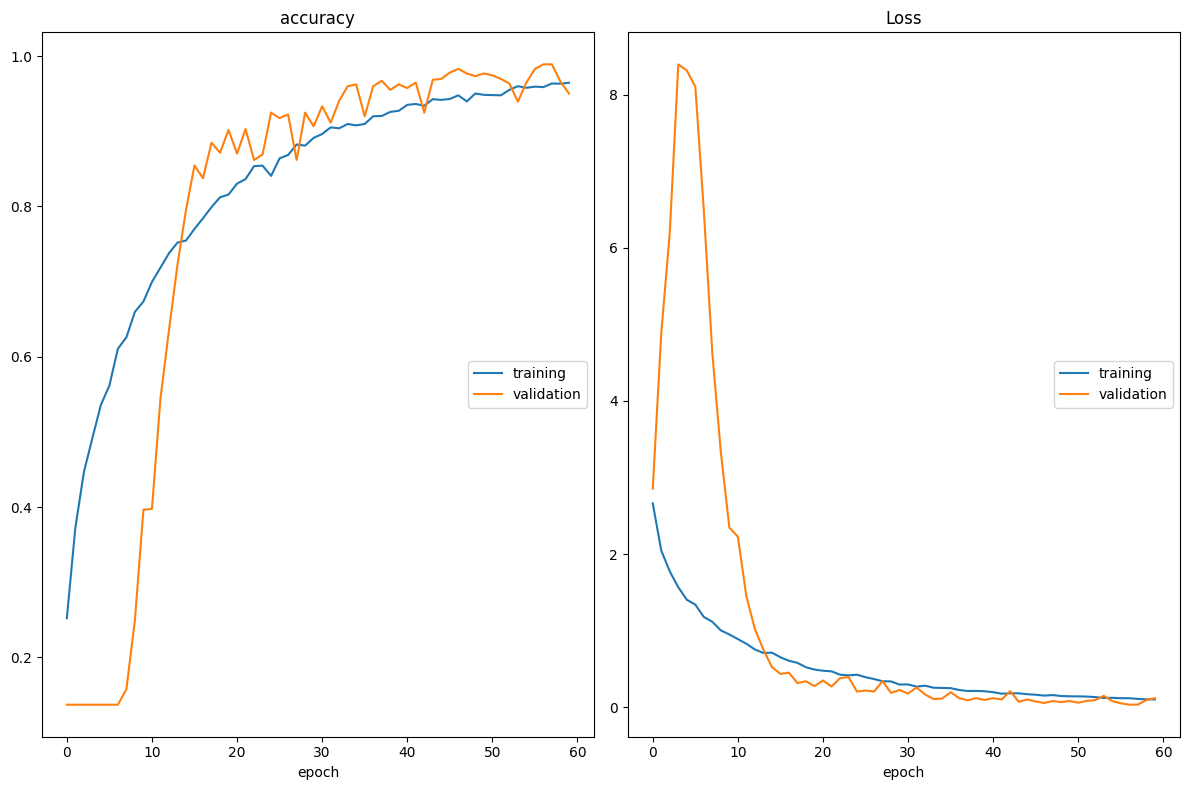

accuracy
	training         	 (min:    0.252, max:    0.965, cur:    0.965)
	validation       	 (min:    0.137, max:    0.989, cur:    0.950)
Loss
	training         	 (min:    0.102, max:    2.663, cur:    0.103)
	validation       	 (min:    0.033, max:    8.397, cur:    0.119)

Epoch 60: val_accuracy did not improve from 0.98909
52/52 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.9662 - loss: 0.1022 - val_accuracy: 0.9503 - val_loss: 0.1186
Restoring model weights from the end of the best epoch: 57.

📊 Final Test Raporu Hazırlanıyor...


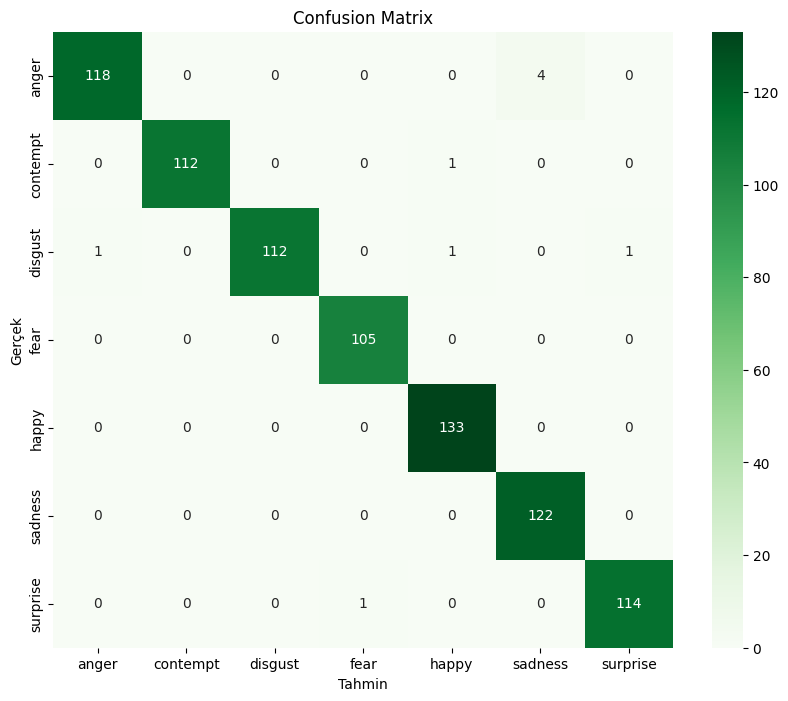


--- DETAYLI BAŞARI RAPORU ---
              precision    recall  f1-score   support

       anger       0.99      0.97      0.98       122
    contempt       1.00      0.99      1.00       113
     disgust       1.00      0.97      0.99       115
        fear       0.99      1.00      1.00       105
       happy       0.99      1.00      0.99       133
     sadness       0.97      1.00      0.98       122
    surprise       0.99      0.99      0.99       115

    accuracy                           0.99       825
   macro avg       0.99      0.99      0.99       825
weighted avg       0.99      0.99      0.99       825


✅ Model başarıyla Drive'a yedeklendi: /content/drive/MyDrive/En_Iyi_Duygu_Modelim.h5


In [31]:
# --- GEREKLİ KÜTÜPHANELERİ KURMA ---
!pip install livelossplot --quiet

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers
from tensorflow.keras.preprocessing.image import load_img, img_to_array, save_img, ImageDataGenerator
import shutil
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from livelossplot import PlotLossesKeras
from google.colab import drive

# ==========================================
# 1. HAZIRLIK VE VERİ YÜKLEME
# ==========================================

# Drive Bağlantısı
drive.mount('/content/drive')

# Yollar (Klasör isimlerini kontrol edin!)
drive_path = '/content/drive/MyDrive/DuyguVeriseti'
local_path = '/content/dataset_raw'
augmented_path = '/content/dataset_balanced'

# Temizlik (Eski kalıntıları sil)
if os.path.exists(local_path): shutil.rmtree(local_path)
if os.path.exists(augmented_path): shutil.rmtree(augmented_path)

# Drive'dan Colab'e Hızlı Kopyalama
print("Veriler Colab ortamına çekiliyor...")
if not os.path.exists(drive_path):
    raise ValueError(f"HATA: '{drive_path}' bulunamadı. Lütfen Drive'daki klasör adını kontrol edin.")
shutil.copytree(drive_path, local_path)

# ==========================================
# 2. VERİ DENGELEME (OVERSAMPLING)
# ==========================================
TARGET_COUNT = 600  # Her sınıfı bu sayıya tamamlayacağız
print(f"\n🚀 Veri Dengeleme Başlıyor: Hedef {TARGET_COUNT} Görsel/Sınıf")

shutil.copytree(local_path, augmented_path)

# Veri Türetici Ayarları
datagen = ImageDataGenerator(
    rotation_range=15,      # Hafif döndürme
    zoom_range=0.15,        # Yakınlaştırma
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

classes = sorted(os.listdir(augmented_path))

for cls in classes:
    cls_dir = os.path.join(augmented_path, cls)
    if not os.path.isdir(cls_dir): continue

    current_images = os.listdir(cls_dir)
    count = len(current_images)
    diff = TARGET_COUNT - count

    print(f"  -> Sınıf: {cls.ljust(10)} | Mevcut: {count} | Üretilecek: {diff}")

    if diff <= 0: continue

    generated_count = 0
    while generated_count < diff:
        random_img = np.random.choice(current_images)
        img_path = os.path.join(cls_dir, random_img)

        try:
            img = load_img(img_path, color_mode='grayscale', target_size=(48, 48))
            x = img_to_array(img)
            x = x.reshape((1,) + x.shape)

            for batch in datagen.flow(x, batch_size=1, save_to_dir=cls_dir, save_prefix='aug', save_format='png'):
                generated_count += 1
                break
        except Exception as e:
            continue

print("\n✅ Veri seti eşitlendi! Eğitim başlıyor...")

# ==========================================
# 3. VERİ SETİNİ MODELE HAZIRLAMA
# ==========================================
batch_size = 64 # Stabilite için artırıldı
img_size = (48, 48)

train_ds = tf.keras.utils.image_dataset_from_directory(
    augmented_path,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=img_size,
    color_mode='grayscale',
    label_mode='categorical',
    batch_size=batch_size
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    augmented_path,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=img_size,
    color_mode='grayscale',
    label_mode='categorical',
    batch_size=batch_size
)

class_names = train_ds.class_names
print(f"Sınıflar: {class_names}")

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

# ==========================================
# 4. MODEL MİMARİSİ (STABİL & KOMPAKT CNN)
# ==========================================
model = models.Sequential(name="Final_Stable_Model")
model.add(layers.Input(shape=(48, 48, 1)))

# Eğitim Anında Ekstra Güvenlik (Augmentation)
model.add(layers.RandomFlip("horizontal"))
model.add(layers.RandomRotation(0.05))
model.add(layers.Rescaling(1./255))

# Blok 1
model.add(layers.Conv2D(64, (3, 3), padding='same', activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.MaxPooling2D(pool_size=(2, 2)))
model.add(layers.Dropout(0.2))

# Blok 2
model.add(layers.Conv2D(128, (3, 3), padding='same', activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.MaxPooling2D(pool_size=(2, 2)))
model.add(layers.Dropout(0.3))

# Blok 3
model.add(layers.Conv2D(256, (3, 3), padding='same', activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.MaxPooling2D(pool_size=(2, 2)))
model.add(layers.Dropout(0.4))

# Çıkış
model.add(layers.Flatten())
model.add(layers.Dense(512, activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.Dropout(0.5))
model.add(layers.Dense(len(class_names), activation='softmax'))

# DERLEME: Düşük LR + Gradient Clipping (Dalgalanmayı önler)
optimizer = optimizers.Adam(learning_rate=0.0001, clipnorm=0.5)

model.compile(optimizer=optimizer,
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Callbacks
plot_losses = PlotLossesKeras()
checkpoint = callbacks.ModelCheckpoint('final_model.h5', monitor='val_accuracy', save_best_only=True, mode='max', verbose=1)
early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=1)

# ==========================================
# 5. EĞİTİM
# ==========================================
print("\n🚀 Eğitim Başlıyor...")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=60,
    callbacks=[plot_losses, checkpoint, early_stop]
)

# ==========================================
# 6. SONUÇ RAPORU VE KAYDETME
# ==========================================
print("\n📊 Final Test Raporu Hazırlanıyor...")
best_model = models.load_model('final_model.h5')

y_pred = []
y_true = []

for images, labels in val_ds:
    preds = best_model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels.numpy(), axis=1))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.ylabel('Gerçek')
plt.xlabel('Tahmin')
plt.show()

# Classification Report
print("\n--- DETAYLI BAŞARI RAPORU ---")
print(classification_report(y_true, y_pred, target_names=class_names))

# Modeli Drive'a Yedekle
drive_save_path = '/content/drive/MyDrive/En_Iyi_Duygu_Modelim.h5'
shutil.copy('final_model.h5', drive_save_path)
print(f"\n✅ Model başarıyla Drive'a yedeklendi: {drive_save_path}")